
# 26 从隐含波动率到整张波动率曲面

> **本章要解决的问题**：同一个到期日，不同执行价的隐波为什么不同？不同到期日又怎样拼成一张曲面？曲面上的点，哪些是报价、哪些是插值、哪些根本不能交易？

## 本章导读

第24章讲了 Black–76 定价，第25章讲了希腊字母。这一章讲**波动率曲面**：把“价格”翻译成“隐波”，再把不同执行价、不同到期日的隐波拼成一张图。

本章分六节：

1. 隐波反解：从价格到波动率；
2. 总方差与期限结构；
3. 微笑与偏斜：为什么不是一条平线；
4. 曲面构建：清洗、插值、无套利；
5. SVI：用参数描述整条微笑；
6. 波动率风险溢价与因子。

### 学习目标

- 能用买卖价反解隐波，并判断哪些点不可交易。
- 能算总方差和区间远期方差。
- 能画微笑/偏斜，并解释经济来源。
- 能做蝶式/日历无套利检查。
- 能用 SVI 拟合微笑，并解释 IV−RV。

### 先修

第24章的 Black–76/支付；第25章的 Vega；第05章的凸性；会 scipy。

---

### 环境准备



## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="26 从隐含波动率到整张波动率曲面" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>26 从隐含波动率到整张波动率曲面｜知识图</title>
<desc>本章主线：价格反解成隐波，把执行价×到期日拼成曲面，再用无套利与 SVI 管住插值。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a23" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao23" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag23" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">26</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">从隐含波动率到整张波动率曲面</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：价格反解成隐波，把执行价×到期日拼成曲面，再用无套利与 SVI 管住插值。</text>
<path d="M 174 227.6 L 190 193.6 L 206 159.6 L 222 125.6" fill="none" stroke="#6E7B8B" stroke-width="0.8" stroke-linecap="round" stroke-linejoin="round" opacity="0.6"/>
<path d="M 208 256.4 L 224 222.4 L 240 188.4 L 256 154.4" fill="none" stroke="#6E7B8B" stroke-width="0.8" stroke-linecap="round" stroke-linejoin="round" opacity="0.6"/>
<path d="M 242 276.2 L 258 242.2 L 274 208.2 L 290 174.2" fill="none" stroke="#6E7B8B" stroke-width="0.8" stroke-linecap="round" stroke-linejoin="round" opacity="0.6"/>
<path d="M 276 287 L 292 253 L 308 219 L 324 185" fill="none" stroke="#6E7B8B" stroke-width="0.8" stroke-linecap="round" stroke-linejoin="round" opacity="0.6"/>
<path d="M 310 288.8 L 326 254.8 L 342 220.8 L 358 186.8" fill="none" stroke="#6E7B8B" stroke-width="0.8" stroke-linecap="round" stroke-linejoin="round" opacity="0.6"/>
<path d="M 344 281.6 L 360 247.6 L 376 213.6 L 392 179.6" fill="none" stroke="#6E7B8B" stroke-width="0.8" stroke-linecap="round" stroke-linejoin="round" opacity="0.6"/>
<path d="M 378 265.4 L 394 231.4 L 410 197.4 L 426 163.4" fill="none" stroke="#6E7B8B" stroke-width="0.8" stroke-linecap="round" stroke-linejoin="round" opacity="0.6"/>
<path d="M 412 240.2 L 428 206.2 L 444 172.2 L 460 138.2" fill="none" stroke="#6E7B8B" stroke-width="0.8" stroke-linecap="round" stroke-linejoin="round" opacity="0.6"/>
<path d="M 446 206 L 462 172 L 478 138 L 494 104" fill="none" stroke="#6E7B8B" stroke-width="0.8" stroke-linecap="round" stroke-linejoin="round" opacity="0.6"/>
<path d="M 222 125.6 L 256 154.4 L 290 174.2 L 324 185 L 358 186.8 L 392 179.6 L 426 163.4 L 460 138.2 L 494 104" fill="none" stroke="#1B3A5C" stroke-width="1.6" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 206 159.6 L 240 188.4 L 274 208.2 L 308 219 L 342 220.8 L 376 213.6 L 410 197.4 L 444 172.2 L 478 138" fill="none" stroke="#1B3A5C" stroke-width="1.6" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 190 193.6 L 224 222.4 L 258 242.2 L 292 253 L 326 254.8 L 360 247.6 L 394 231.4 L 428 206.2 L 462 172" fill="none" stroke="#1B3A5C" stroke-width="1.6" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 174 227.6 L 208 256.4 L 242 276.2 L 276 287 L 310 288.8 L 344 281.6 L 378 265.4 L 412 240.2 L 446 206" fill="none" stroke="#E07B39" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 160 330 L 560 330" fill="none" stroke="#6E7B8B" stroke-width="1.2" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag23)"/>
<text x="552" y="346" font-size="9" fill="#6E7B8B" text-anchor="end">K / F（行权价）</text>
<path d="M 160 330 L 160 200" fill="none" stroke="#6E7B8B" stroke-width="1.2" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag23)"/>
<text x="166" y="208" font-size="9" fill="#6E7B8B">σ（隐波）</text>
<path d="M 560 330 L 650 286" fill="none" stroke="#6E7B8B" stroke-width="1.2" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag23)"/>
<text x="654" y="282" font-size="9" fill="#6E7B8B">T（到期）</text>
<circle cx="310" cy="288.8" r="4" fill="#E07B39"/>
<text x="316" y="304.8" font-size="9" fill="#E07B39">ATM 平值</text>
<line x1="430" y1="240" x2="412" y2="240.2" stroke="#6E7B8B" stroke-width="1" stroke-linecap="round" stroke-dasharray="3 3"/>
<text x="436" y="236" font-size="9" fill="#1B3A5C">微笑：两翼隐波更高</text>
<text x="560" y="150" font-size="10" fill="#1B3A5C" font-weight="bold">期限结构</text>
<text x="560" y="168" font-size="8.8" fill="#6E7B8B">不同到期拼成曲面</text>
<text x="560" y="190" font-size="8.8" fill="#6E7B8B">SVI：用参数描述整条微笑</text>
<text x="560" y="208" font-size="8.8" fill="#E07B39">无套利：蝶式 ≥ 0、日历 ≥ 0</text>
<rect x="43" y="344" width="165" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="125.5" y="355.4" font-size="10.5" fill="#1B3A5C" text-anchor="middle">反解隐波</text>
<text x="125.5" y="369.9" font-size="8.5" fill="#6E7B8B" text-anchor="middle">买卖价各一个解</text>
<rect x="226" y="344" width="165" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="308.5" y="355.4" font-size="10.5" fill="#1B3A5C" text-anchor="middle">微笑与偏斜</text>
<text x="308.5" y="369.9" font-size="8.5" fill="#6E7B8B" text-anchor="middle">同一到期、不同 K</text>
<rect x="409" y="344" width="165" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="491.5" y="355.4" font-size="10.5" fill="#1B3A5C" text-anchor="middle">总方差与期限</text>
<text x="491.5" y="369.9" font-size="8.5" fill="#6E7B8B" text-anchor="middle">不同到期拼成面</text>
<rect x="592" y="344" width="165" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="674.5" y="355.4" font-size="10.5" fill="#1B3A5C" text-anchor="middle">无套利 / SVI</text>
<text x="674.5" y="369.9" font-size="8.5" fill="#6E7B8B" text-anchor="middle">蝶式、日历检查</text>
<path d="M 211 365 L 223 365" fill="none" stroke="#6E7B8B" stroke-width="1.2" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag23)"/>
<path d="M 394 365 L 406 365" fill="none" stroke="#6E7B8B" stroke-width="1.2" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag23)"/>
<path d="M 577 365 L 589 365" fill="none" stroke="#6E7B8B" stroke-width="1.2" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag23)"/>
</svg>

> **图**：本章主线：价格反解成隐波，把执行价×到期日拼成曲面，再用无套利与 SVI 管住插值。


In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：波动率交易员、期权研究员、风控。
- **输入**：期权链、期货价、买卖价、到期/执行价。
- **输出**：隐波、总方差、微笑/偏斜、SVI 参数、无套利检查、VRP。
- **在流程的哪一步**：波动率定价与曲面构建。
- **失败模式**：中间价当可成交、旧期权价配新期货价、插值后不查套利。
- **最小工作流**：期权链清洗 → 反解 IV → 总方差 → 微笑/蝶式/日历 → SVI → VRP。

---
## 1. 隐波反解：从价格到波动率

### 1.1 定义

隐含波动率是“让模型价等于市场价”的波动率：

$$\text{Black76}(F,K,T,\sigma_{\text{imp}})=P_{\text{market}}.$$

它不是“预测的波动率”，而是市场报价翻译出来的一个数。

### 1.2 买卖价各一个解

买价、卖价分别反解，得到隐波区间：

- 买价隐波低；
- 卖价隐波高；
- 中间价隐波只是研究标记，不代表可成交。

### 1.3 边界

反解前先检查价格是否在无套利区间：

$$e^{-rT}\max(F-K,0)\le C\le e^{-rT}F.$$

价格越界，可能没有解；先查时间戳、合约、单位。

### 1.4 代码：定价与反解



In [2]:

import numpy as np
from scipy.special import ndtr
from scipy.optimize import brentq

def black76(F, K, T, vol, r=0.02, kind="call"):
    if T == 0:
        return max(F - K, 0) if kind == "call" else max(K - F, 0)
    w = vol * np.sqrt(T)
    d1 = (np.log(F / K) + 0.5 * w * w) / w
    d2 = d1 - w
    if kind == "call":
        return np.exp(-r * T) * (F * ndtr(d1) - K * ndtr(d2))
    return np.exp(-r * T) * (K * ndtr(-d2) - F * ndtr(-d1))

def implied(price, F, K, T, r=0.02, kind="call"):
    return brentq(lambda v: black76(F, K, T, v, r, kind) - price, 1e-6, 5.0)

price = black76(100, 100, 0.5, 0.25)
print("模型价", round(price, 4))
print("反解隐波", round(implied(price, 100, 100, 0.5), 4))


模型价 6.9731
反解隐波 0.25



**读数与应用**：模型价 6.9731，反解回 0.25。真实市场里，买价/卖价会反解出两个不同的隐波；点差越宽，隐波区间越大。

**常见错误**：

1. 用现货价代替期货价。
2. 用历史波动率代替隐含波动率。
3. 价格越界还硬解，得到负数/极大值。

**停下来想一想**：为什么深虚值期权的一点报价误差会放大成很大的隐波误差？

<details><summary>对照你的思路</summary>

深虚值期权的 Vega 很小，价格对波动率不敏感；反解时，价格的小误差除以小 Vega，隐波误差被放大。所以深虚值的隐波最不可靠，要保留买卖区间。

</details>

---



## 2. 总方差与期限结构

### 2.1 总方差

$$\text{Total Variance}=\sigma^2T.$$

它把“波动率”和“时间”合成一个量，便于跨期限比较。

### 2.2 区间远期方差

若两个期限的总方差为 $w_1=\sigma_1^2T_1$、$w_2=\sigma_2^2T_2$，则 $[T_1,T_2]$ 的区间方差：

$$\sigma_{1,2}^2=\frac{w_2-w_1}{T_2-T_1}.$$

**公式拆解**
- **符号**：$w=\sigma^2T$ 为总方差，$\sigma$ 年化隐波，$T$ 年；$w_1,w_2$ 为近远月。
- **结构**：总方差对时间的斜率 $(w_2-w_1)/(T_2-T_1)$，用于跨期限比较。
- **代入**：$T_1=0.25,\sigma_1=20\%$、$T_2=0.5,\sigma_2=18\%$：$w_1=0.01,w_2=0.0162$，区间方差 $=0.0248$。
- **边界**：$T_2=T_1$ 时分母为 0；$w_2<w_1$ 违反日历无套利。
- **用途**：比期限、算远期方差；不能直接比隐波或预测 RV。

### 2.3 日历无套利

总方差必须随期限不下降：

$$w(T_2)\ge w(T_1)\quad(T_2>T_1).$$

否则可以“买近月、卖远月”套利（忽略成本/流动性）。

### 2.4 代码：总方差与区间方差



In [3]:

import numpy as np

times = np.array([0.25, 0.50])
iv = np.array([0.20, 0.18])
total = iv ** 2 * times

print("总方差", total.round(4))
print("区间年化方差", np.sqrt(np.diff(total) / np.diff(times)).round(4))


总方差 [0.01   0.0162]
区间年化方差 [0.1575]



**读数与应用**：近月隐波 20%、远月 18%，但远月总方差更高；区间方差约 15.75%。**不要直接比较两个期限的隐波，要先转总方差。**

**常见错误**：

1. 直接比较 20% 和 18%，说“远月更便宜”。
2. 用标准差相减，而不是方差相加。
3. 不同标的/不同到期月硬拼期限结构。

**停下来想一想**：远月隐波更低，为什么总风险可能更大？

<details><summary>对照你的思路</summary>

总方差是 $\sigma^2T$；远月时间更长，即使年化波动率低，累积的总方差也可能更高。期权价格看的是总方差，不是单看年化隐波。

</details>

---



## 3. 微笑与偏斜：为什么不是一条平线

### 3.1 现象

同一到期日，不同执行价的隐波通常不是平的：

- 两端高、中间低：微笑；
- 一侧系统性更高：偏斜（skew）。

### 3.2 坐标

用相对执行价：

$$k=\ln\frac{K}{F}.$$

$k=0$ 是平值；$k>0$ 是虚值看涨/实值看跌；$k<0$ 反之。

### 3.3 经济来源

- 收益分布有厚尾/跳跃，不是对数正态；
- 买方对尾部保护有需求；
- 供需/流动性/做市商库存；
- 杠杆效应：下跌时波动率上升。

### 3.4 代码：一条微笑



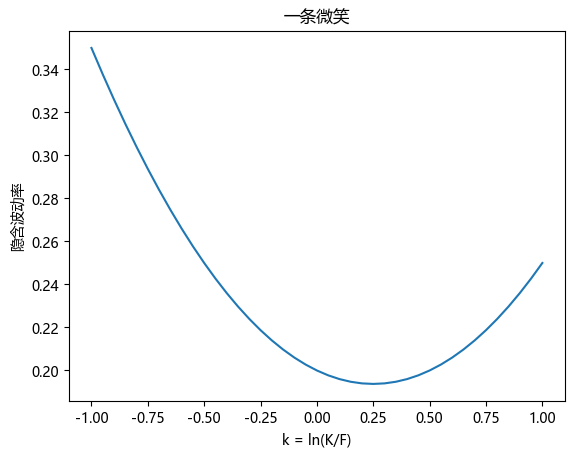

In [4]:

import numpy as np
import matplotlib.pyplot as plt

k = np.linspace(-1, 1, 41)
iv = 0.20 - 0.05 * k + 0.10 * k ** 2

plt.plot(k, iv)
plt.xlabel("k = ln(K/F)")
plt.ylabel("隐含波动率")
plt.title("一条微笑")
plt.show()



**读数与应用**：这条曲线两端高、中间低，是典型的微笑。真实商品的偏斜可能更陡，且随到期日变化。

**常见错误**：

1. 用固定行权价比较不同期货价的合约；要用 $k=\ln(K/F)$。
2. 把微笑当成“市场预测”。
3. 忽略买卖价差，只看中间价微笑。

**停下来想一想**：为什么“下跌时隐波上升”会让看跌期权更贵？

<details><summary>对照你的思路</summary>

下跌时波动率上升，看跌期权更可能进入实值，且尾部风险溢价上升；Vega 为正，隐波上升直接推高看跌价格。这也是“偏斜”存在的原因之一。

</details>

---



## 4. 曲面构建：清洗、插值、无套利

### 4.1 数据管道

从原始期权链到曲面，至少做：

1. 合约映射：同一标的、同一到期月、同一行权方式；
2. 时间戳：期权价和期货价要同步；
3. 买卖价：保留 bid/ask，不只取中间价；
4. 边界：剔除没有隐波解的价格；
5. 插值：按 $k=\ln(K/F)$ 和总方差插值；
6. 无套利：蝶式、日历、垂直价差。

### 4.2 蝶式无套利

看涨价差的价格必须随执行价递减且凸：

$$\frac{\partial C}{\partial K}\le0,\qquad \frac{\partial^2C}{\partial K^2}\ge0.$$

离散版：二阶差分 $\ge0$。若某个执行价让二阶差分为负，说明报价有问题或存在套利。

**公式拆解**
- **符号**：$C(K)$ 为看涨价，$K_1<K_2<K_3$ 等距。
- **结构**：$\partial C/\partial K\le0$ 且 $\partial^2C/\partial K^2\ge0$，即蝶式 $C(K_1)-2C(K_2)+C(K_3)\ge0$。
- **代入**：$K=90,100,110$ 的价格 $11.78,5.58,2.10$：蝶式 $=11.78-11.16+2.10=2.72>0$。
- **边界**：$\sigma\to0$ 时蝶式趋 0；极虚值处坏报价会打成负。
- **用途**：清洗曲面；二阶差为正只是约束，不是信号。

### 4.3 日历无套利

总方差随期限不下降（见第 2 节）。

### 4.4 代码：蝶式检查



In [5]:

import numpy as np

K = np.array([80.0, 90.0, 100.0, 110.0, 120.0])
k = np.log(K / 100.0)
iv = 0.20 - 0.05 * k + 0.10 * k ** 2
prices = np.array([black76(100.0, ki, 0.5, vi) for ki, vi in zip(K, iv)])

print("看涨价", prices.round(3))
print("蝶式二阶差", np.diff(prices, 2).round(4))


看涨价 [20.234 11.784  5.581  2.1    0.638]
蝶式二阶差 [2.2471 2.7217 2.0196]



**读数与应用**：二阶差分为正，说明这条微笑对应的看涨价是凸的；若某点为负，要回查报价/时间戳/合约映射，不能直接插值。

**常见错误**：

1. 用中间价算曲面，再用市价单成交。
2. 不同到期月的期货价混用。
3. 插值后再检查套利；应该先清洗、再插值、再检查。

**停下来想一想**：为什么蝶式价格为负是“套利”？

<details><summary>对照你的思路</summary>

蝶式组合（买低 K、卖两份中 K、买高 K）在所有终值下支付非负；若今天价格为负，等于“别人付钱让你持有非负支付”，就是套利。二阶差分负，等价于蝶式价格为负。

</details>

---



## 5. SVI：用参数描述整条微笑

### 5.1 公式

SVI 用总方差 $w(k)$ 描述微笑：

$$w(k)=a+b\left(\rho(k-m)+\sqrt{(k-m)^2+\sigma^2}\right).$$

- $a$：整体水平；
- $b$：斜率尺度；
- $\rho$：偏斜方向；
- $m$：微笑中心；
- $\sigma$：平滑度。

**公式拆解**
- **符号**：$k=\ln(K/F)$，$w=\sigma^2T$；$a,b,\rho,m,\sigma$ 为 5 参数。
- **结构**：$w=a+b[\rho(k-m)+\sqrt{(k-m)^2+\sigma^2}]$，两翼斜率趋 $b(\rho\pm1)$。
- **代入**：$a=0,b=0.044,\rho=-0.57,m=-0.25,\sigma=0.52$：$k=0$ 时 $w\approx0.019$，隐波约 19.6%。
- **边界**：$b=0$ 退化为常数；$|\rho|\to1$ 时一翼过陡
- **用途**：5 参数概括微笑；拟合好≠可交易

### 5.2 拟合

给定一组 $(k_i,w_i)$，最小化：

$$\sum_i\left(w(k_i;\theta)-w_i\right)^2.$$

参数有约束：$b\ge0$、$|\rho|<1$、$\sigma>0$，还要检查无套利。

### 5.3 代码：SVI 拟合



In [6]:

import numpy as np
from scipy.optimize import least_squares

k = np.linspace(-1, 1, 41)
iv_true = 0.20 - 0.05 * k + 0.10 * k ** 2
w_true = iv_true ** 2 * 0.5

def svi(k, a, b, rho, m, sigma):
    return a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + sigma ** 2))

res = least_squares(
    lambda p: svi(k, *p) - w_true,
    x0=[0.01, 0.05, -0.3, 0.0, 0.1],
    bounds=([0.0, 0.0, -0.99, -1.0, 0.001], [1.0, 1.0, 0.99, 1.0, 1.0]),
)
print("拟合参数", res.x.round(4))
print("残差平方和", round(np.sum(res.fun ** 2), 8))


拟合参数 [ 0.      0.0438 -0.5658 -0.2454  0.5213]
残差平方和 4.913e-05



**读数与应用**：SVI 用 5 个参数概括整条微笑；拟合好不代表无套利，还要检查蝶式/日历。真实曲面常用 SVI/SSVI 做参数化，再做套利约束。

**常见错误**：

1. 只拟合中间价，不看买卖区间。
2. 拟合后不检查无套利。
3. 用同一组参数跨品种/跨期，忽略结构变化。

**停下来想一想**：SVI 拟合残差很小，是否说明曲面可交易？

<details><summary>对照你的思路</summary>

不说明。拟合残差小只说明“曲线贴合报价”，不代表报价可成交、曲面无套利、容量足够。还要看买卖价差、深度、时间戳、蝶式/日历约束。

</details>

---



## 6. 波动率风险溢价与因子

### 6.1 IV 与 RV

- 隐含波动率（IV）：市场对未来的定价；
- 已实现波动率（RV）：过去/未来实际发生的波动。

两者之差：

$$\text{VRP}_t=IV_t^2-RV_{t+h}^2.$$

注意：用“未来 RV”算的是事后评价，不是今天可用的信号；今天只能用“过去 RV”做特征。

**公式拆解**
- **符号**：$\text{IV}_t$ 为隐含波动率，$\text{RV}_{t+h}$ 为已实现波动率，均为年化小数。
- **结构**：$\text{VRP}_t=\text{IV}_t^2-\text{RV}_{t+h}^2$，两边都用方差而不是波动率。
- **代入**：IV$=25\%$、RV$=20\%$：$0.0625-0.04=0.0225$，波动率点差 5 个点。
- **边界**：RV$>$IV 时 VRP 为负；未来 RV 今天不可见，不能进信号。
- **用途**：研究卖波动率溢价、做 IV−RV 因子；IV 高不等于该卖。

### 6.2 因子

- IV 期限结构（近远月差）；
- 偏斜（虚值看跌 vs 虚值看涨）；
- IV−RV 溢价；
- 曲面变化（水平/斜率/曲率）。

### 6.3 代码：IV−RV



In [7]:

iv, rv = 0.25, 0.20
print("方差差", round(iv ** 2 - rv ** 2, 4))
print("波动率点差", round((iv - rv) * 100, 2))


方差差 0.0225
波动率点差 5.0



**读数与应用**：IV 25%、RV 20%，方差差 0.0225、波动率点差 5 点。高 IV 不代表一定做空；还要看未来 RV、跳空、成本和保证金。

**常见错误**：

1. 用未来 RV 当今天信号。
2. 只看 IV 高，不看偏斜/期限。
3. 忽略卖方的尾部风险。

**停下来想一想**：IV 高、RV 低，是否就该卖期权？

<details><summary>对照你的思路</summary>

不一定。IV 高可能反映市场对跳空/事件的定价；RV 低是过去，未来可能突然升高。卖方收益有限、尾部风险大，还要看保证金、对冲成本、流动性。VRP 是一个研究假设，不是自动交易信号。

</details>

---



## 本章小结

### 一张表

| 概念 | 公式/做法 | 用途 |
|---|---|---|
| 隐波 | Black76 反解 | 价格→波动率 |
| 总方差 | $\sigma^2T$ | 跨期限比较 |
| 区间方差 | $(w_2-w_1)/(T_2-T_1)$ | 远期波动 |
| 微笑 | $k=\ln(K/F)$ | 偏斜 |
| 蝶式 | $\partial^2C/\partial K^2\ge0$ | 无套利 |
| 日历 | $w(T_2)\ge w(T_1)$ | 无套利 |
| SVI | $w=a+b(\rho(k-m)+\sqrt{(k-m)^2+\sigma^2})$ | 参数化 |
| VRP | $IV^2-RV^2$ | 风险溢价 |

### 八句话

1. 隐波是报价翻译，不是预测。
2. 买价/卖价各一个隐波，中间价只是标记。
3. 比较期限先转总方差。
4. 远月隐波低，总方差可能更高。
5. 微笑/偏斜来自厚尾、供需、杠杆效应。
6. 曲面先清洗、再插值、再检查无套利。
7. SVI 拟合好不代表可交易。
8. VRP 是假设，不是自动信号。

---

## 本章习题

**1.** 模型价 6.97，反解隐波 0.25。若市场买价对应隐波 0.24、卖价 0.27，中间价隐波是多少？能按中间价成交吗？

**2.** 近月 0.25 年、隐波 20%；远月 0.5 年、隐波 18%。求总方差和区间方差。

**3.** 为什么远月隐波更低，总方差可能更高？

**4.** 蝶式二阶差分为负，说明什么？

**5.** 日历无套利要求总方差怎样？

**6.** SVI 的 5 个参数各代表什么？

**7.** IV 25%、RV 20%，求方差差和波动率点差。

**8.** 为什么 IV 高、RV 低不一定该卖期权？

<details><summary>参考答案</summary>

**1.** 中间价隐波约 $(0.24+0.27)/2=0.255$；不能保证按中间价成交，实际只能按买/卖价。

**2.** 总方差 $0.04\times0.25=0.01$、$0.0324\times0.5=0.0162$；区间方差 $(0.0162-0.01)/0.25=0.0248$，年化约 15.75%。

**3.** 总方差 $=\sigma^2T$；远月时间更长，累积方差可能更高。

**4.** 看涨价不凸，可能存在蝶式套利或报价错误。

**5.** 总方差随期限不下降。

**6.** $a$ 水平、$b$ 斜率尺度、$\rho$ 偏斜、$m$ 中心、$\sigma$ 平滑度。

**7.** 方差差 $0.0625-0.04=0.0225$；点差 5 点。

**8.** IV 高可能反映事件/跳空风险；RV 是过去，未来可能升高；卖方还有保证金、尾部风险、成本。

</details>

---

## 参考资料

- Gatheral, J. *The Volatility Surface*（SVI/曲面）。
- Hull, J. C. *Options, Futures, and Other Derivatives*（隐波/微笑）。
- CBOE 波动率指数方法论文档。
